In [1]:
print("Let's Start")

Let's Start


Gamma

In [19]:
import pandas as pd
import xgboost as xgb
from sklearn.datasets import load_diabetes
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.metrics import r2_score

In [8]:
x , y = load_diabetes(return_X_y=True)
x_train , x_test , y_train , y_test = train_test_split(x , y, test_size=0.2, random_state=42)
x_train.shape , x_test.shape , y_train.shape , y_test.shape

((353, 10), (89, 10), (353,), (89,))

In [26]:
def param_tester(
    x,
    y,
    parameter_name,
    parameter_values,
    *,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    random_state=42,
    estimator_params=None,
):
    """Evaluate one XGBoost regressor parameter using cross-validation."""
    if not isinstance(parameter_name, str) or not parameter_name:
        raise ValueError("parameter_name must be a non-empty string")

    cv_splitter = KFold(n_splits=cv, shuffle=True, random_state=random_state)
    base_params = dict(estimator_params or {})
    base_params["random_state"] = random_state
    base_params["n_jobs"] = 1

    scores = []
    for value in parameter_values:
        model_params = {**base_params, parameter_name: value}
        model = xgb.XGBRegressor(**model_params)
        fold_scores = cross_val_score(
            model,
            x,
            y,
            cv=cv_splitter,
            scoring=scoring,
            n_jobs=n_jobs,
            error_score="raise",
        )
        scores.append(fold_scores.mean())

    return scores

In [29]:
gammas = [0 , 100 , 200 , 300 , 400 , 500 , 1000]

print(param_tester(x , y, 'min_split_loss' , gammas))

[np.float64(0.3289898428422317), np.float64(0.33219926360539176), np.float64(0.3155737524560121), np.float64(0.33085296498719474), np.float64(0.3139080362223413), np.float64(0.3166729532127503), np.float64(0.3268644446944801)]


MAx Depth

In [33]:
maxDepths = [0, 2 , 4,  6, 8,10]
print(param_tester(x ,  y, 'max_depth' , maxDepths))

[np.float64(0.23363923046199014), np.float64(0.36606239198404034), np.float64(0.32814104790829557), np.float64(0.3289898428422317), np.float64(0.28259448969755663), np.float64(0.2325818618053927)]


In [45]:
# One-at-a-time sample spaces: each parameter is varied while the others stay at these baselines.
parameter_spaces = {
    "n_estimators": range(50, 501, 50),
    "learning_rate": [0.01, 0.025, 0.05, 0.075, 0.1, 0.15, 0.2, 0.3 , 0.5 ,0.8 ,1]  ,
    "max_depth": range(1, 11),
    "min_child_weight": range(1, 11),
    "subsample": [0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    "gamma": [0, 0.1, 0.25, 0.5, 1, 2, 5, 10],
    "reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10],
    "reg_lambda": [0.1, 0.5, 1, 2, 5, 10, 20],
    "max_delta_step": [0, 1, 2, 5, 10],
}

baseline_params = {
    "n_estimators": 200,
    "learning_rate": 0.1,
    "max_depth": 3,
    "min_child_weight": 1,
    "subsample": 1.0,
    "colsample_bytree": 1.0,
    "gamma": 0,
    "reg_alpha": 0,
    "reg_lambda": 1,
    "max_delta_step": 0,
}

parameter_results = {
    name: param_tester(
        x,
        y,
        name,
        values,
        cv=3,
        estimator_params=baseline_params,
    )
    for name, values in parameter_spaces.items()
}

results = pd.DataFrame(
    [
        {"parameter": name, "value": value, "mean_cv_r2": score}
        for name, values in parameter_spaces.items()
        for value, score in zip(values, parameter_results[name])
    ]
)
results.sort_values(["parameter", "mean_cv_r2"], ascending=[True, False]).reset_index(drop=True)

,parameter,value,mean_cv_r2
0,colsample_bytree,0.8,0.379623
1,colsample_bytree,0.7,0.375621
2,colsample_bytree,0.5,0.366486
3,colsample_bytree,0.6,0.363984
4,colsample_bytree,1.0,0.361788
...,...,...,...
74,subsample,1.0,0.361788
75,subsample,0.8,0.350200
76,subsample,0.7,0.347914
77,subsample,0.9,0.342923


In [37]:
sc_bt = results[results['parameter'] == 'colsample_bytree']

In [64]:
params = results['parameter'].unique().tolist()

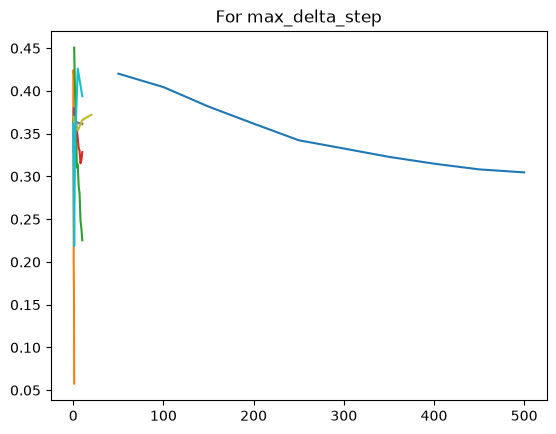

In [ ]:
import matplotlib.pyplot as plt
for i in range(len(params)):
    sc_bt = results[results['parameter'] == params[i]]
    plt.plot(sc_bt['value'] , sc_bt['mean_cv_r2'])
    plt.title(f'For {params[i]}')
    plt.show()

In [ ]:
o